# Задание 4.12

**(Продолжение)** Пусть $n$ лиц имеют время ожидания $w_1,w_2,\dots,w_n$, выраженное в долях от общего интервала времени. Считая, что момент прихода на встречу выбирается каждым «наудачу» в пределах указанного часа, докажите, что вероятность того, что встреча состоится, определяется следующими равенствами для **a)** $n=2$; **b)** $n=3$; **c)** $n=3$, $w_1=\frac14$, $w_2=\frac13$, $w_3=\frac12$ (15 минут, 20 минут, 30 минут); **d)** $n=4$:

$$
\begin{aligned}
&a)\ P_2=1-\frac{(1-w_1)^2}{2}-\frac{(1-w_2)^2}{2};\\
&b)\ P_3=w_1w_2+w_1w_3+w_2w_3-\frac12\left(w_1w_2^2+w_1w_3^2+w_2w_3^2\right)-\frac13w_1^3-\frac16w_2^3;\\
&c)\ P_3=\frac{1435}{5184}=0{,}27681;\\
&d)\ P_4=w_1w_2w_3+w_1w_2w_4+w_1w_3w_4+w_2w_3w_4-\frac{w_4^2}{2}(w_1w_2+w_1w_3+w_2w_3)-\frac{w_3^3}{6}(w_1+w_2)-\frac{w_1w_2w_3^2}{2}-\frac{w_1w_2^3}{3}-\frac{w_1^4}{4}-\frac{w_2^4}{12}.
\end{aligned}
$$

*Общее требование листка:* ко всем задачам, где есть числовой ответ, напишите программу (код) с использованием инструментария **Jupyter Notebook**, который иллюстрирует график зависимости относительной частоты $\hat p(A)\overset{\text{def}}{=}\dfrac{N(A)}{N}$ события $A$ от числа проведённых реализаций опыта $N$.

## Теория

**Модель.** $t_1,\dots,t_n$ — независимые равномерные на $[0,1]$ моменты прихода. Лицо $i$ находится на месте в течение $[t_i,\ t_i+w_i]$. Встреча всех состоится ⇔ все эти отрезки имеют общую точку ⇔ последний пришедший застаёт всех остальных:

$$
M=\{\,t_{\max}-t_j\le w_j\ \ \forall j\,\},\qquad t_{\max}=\max_i t_i .
$$

(Сам последний ждать не должен, поэтому его $w$ не важен.) Формулы b) и d) записаны для упорядоченных $w_1\le w_2\le\dots\le w_n$ — в этом виде они и доказываются.

**Общая формула.** Разобьём $M$ на несовместные события «последним пришёл $k$-й». Если $t_k=t$, то каждый $j\ne k$ должен прийти в $[t-w_j,\ t]\cap[0,1]$ — отрезок длины $\min(w_j,t)$. Интегрируем по $t$:

$$
\boxed{\ P_n=\sum_{k=1}^{n}\int_0^1\prod_{j\ne k}\min(w_j,t)\,dt\ }
$$

**Базовые интегралы** (при $w_a\le w_b\le w_c$; интеграл разбиваем точками $w_a,w_b,w_c$):

$$
\int_0^1\min(w_a,t)\,dt=w_a-\frac{w_a^2}{2},
$$

$$
\int_0^1\min(w_a,t)\min(w_b,t)\,dt=\frac{w_a^3}{3}+\frac{w_a(w_b^2-w_a^2)}{2}+w_aw_b(1-w_b)=w_aw_b-\frac{w_aw_b^2}{2}-\frac{w_a^3}{6},
$$

$$
\int_0^1\min(w_a,t)\min(w_b,t)\min(w_c,t)\,dt=w_aw_bw_c-\frac{w_aw_bw_c^2}{2}-\frac{w_aw_b^3}{6}-\frac{w_a^4}{12}.
$$

**a) $n=2$:** $P_2=\left(w_1-\frac{w_1^2}{2}\right)+\left(w_2-\frac{w_2^2}{2}\right)=1-\frac{(1-w_1)^2}{2}-\frac{(1-w_2)^2}{2}$ — квадрат без двух треугольников.

**b) $n=3$:** складываем три парных интеграла по парам $(1,2),(1,3),(2,3)$:

$$
P_3=\sum_{a<b}w_aw_b-\frac12\left(w_1w_2^2+w_1w_3^2+w_2w_3^2\right)-\frac{w_1^3}{6}-\frac{w_1^3}{6}-\frac{w_2^3}{6},
$$

что совпадает с b).

**c)** Подставляем $w=(\frac14,\frac13,\frac12)$: $\ \frac38-\frac{25}{288}-\frac{1}{192}-\frac{1}{162}=\frac{1944-450-27-32}{5184}=\frac{1435}{5184}\approx0{,}27681$.

**d) $n=4$:** сумма четырёх тройных интегралов по тройкам $(1,2,3),(1,2,4),(1,3,4),(2,3,4)$:

$$
\sum w_aw_bw_c-\tfrac12\big(w_1w_2w_3^2+w_4^2(w_1w_2+w_1w_3+w_2w_3)\big)-\tfrac16\big(2w_1w_2^3+w_1w_3^3+w_2w_3^3\big)-\tfrac{1}{12}\big(3w_1^4+w_2^4\big),
$$

что после группировки совпадает с d).

*Частный случай* $w_1=\dots=w_n=q$: $\ P_n=n\left(\frac{q^n}{n}+q^{n-1}(1-q)\right)=nq^{n-1}-(n-1)q^n$ — формула задачи 4.11.

В коде формулы проверяются символьно (sympy), численно для случайных $w$ и моделированием.

n = 2: общая формула − формула из условия = 0
n = 3: общая формула − формула из условия = 0
n = 4: общая формула − формула из условия = 0
c) P_3 = 1435/5184 = 0.27681


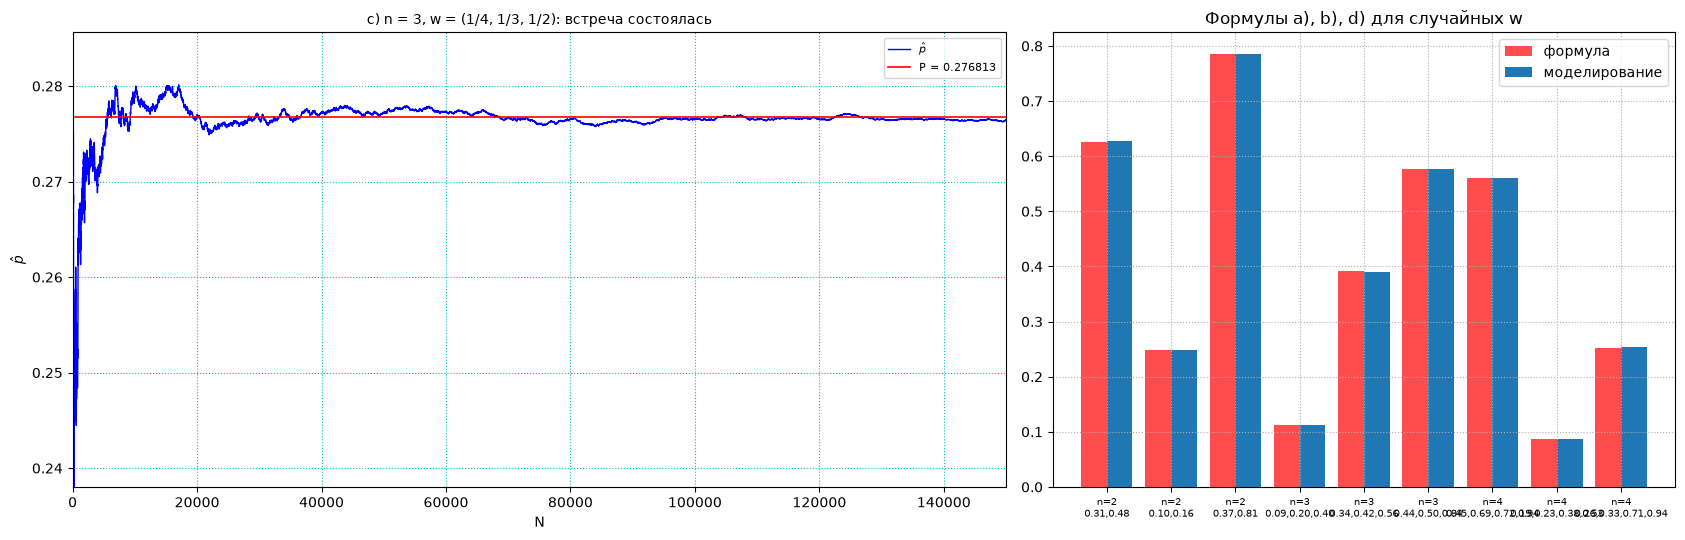

c) p̂ = 0.27642 при N = 150 000
n = 2, w = [0.309 0.48 ]: формула 0.62620,  моделирование 0.62770
n = 2, w = [0.102 0.165]: формула 0.24753,  моделирование 0.24798
n = 2, w = [0.371 0.813]: формула 0.78493,  моделирование 0.78541
n = 3, w = [0.094 0.204 0.404]: формула 0.11177,  моделирование 0.11148
n = 3, w = [0.335 0.418 0.563]: формула 0.39106,  моделирование 0.38945
n = 3, w = [0.443 0.5   0.841]: формула 0.57595,  моделирование 0.57613
n = 4, w = [0.455 0.686 0.724 0.941]: формула 0.56055,  моделирование 0.55992
n = 4, w = [0.188 0.228 0.384 0.529]: формула 0.08691,  моделирование 0.08708
n = 4, w = [0.264 0.328 0.712 0.942]: формула 0.25248,  моделирование 0.25322


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from itertools import combinations

rng = np.random.default_rng(2026)

def plot_freq(ax, hits, p, title, cond=None, skip=None):
    """График относительной частоты p̂ = N(A)/N от числа опытов N (красная линия — точная вероятность p).
    Если задано cond — строится условная частота N(A∩B)/N(B)."""
    hits = np.asarray(hits, dtype=bool)
    n = np.arange(1, hits.size + 1)
    if cond is None:
        freq = np.cumsum(hits) / n                                   # p̂(A) после каждого опыта
    else:
        nb = np.cumsum(cond)
        freq = np.where(nb > 0, np.cumsum(hits & cond) / np.maximum(nb, 1), np.nan)  # p̂(A|B)
    step = max(1, hits.size // 20000)                                # прореживаем точки для отрисовки
    ax.plot(n[::step], freq[::step], color="blue", lw=1, label=r"$\hat p$")
    ax.axhline(p, color="red", lw=1.2, label=f"P = {p:.6f}")
    skip = skip or max(50, hits.size // 300)                         # первые опыты — сильный разброс
    lo, hi = np.nanmin(freq[skip:]), np.nanmax(freq[skip:])
    lo, hi = min(lo, p), max(hi, p)
    pad = 0.15 * (hi - lo) + 1e-12
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, hits.size)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("N")
    ax.set_ylabel(r"$\hat p$")
    ax.grid(ls=":", color="c")
    ax.legend(fontsize=8, loc="upper right")
    return freq[-1]


def P_general(ws):
    """P_n = Σ_k ∫_0^1 Π_{j≠k} min(w_j, t) dt для упорядоченных символьных/числовых w1 ≤ ... ≤ wn.
    Интеграл берётся по участкам [0, w1], [w1, w2], ..., [wn, 1], на которых min(w_j, t) — многочлен."""
    t = sp.symbols("t")
    n = len(ws)
    pts = [0] + list(ws) + [1]
    total = 0
    for others in combinations(range(n), n - 1):            # множество тех, кого застаёт последний
        for i in range(len(pts) - 1):                       # участок [pts[i], pts[i+1]]: w_j < t для j < i
            f = sp.Mul(*[ws[j] if j < i else t for j in others])
            total += sp.integrate(f, (t, pts[i], pts[i + 1]))
    return sp.expand(total)


w1, w2, w3, w4 = sp.symbols("w1 w2 w3 w4", positive=True)
formulas = {
    2: 1 - (1 - w1)**2/2 - (1 - w2)**2/2,
    3: w1*w2 + w1*w3 + w2*w3 - sp.Rational(1, 2)*(w1*w2**2 + w1*w3**2 + w2*w3**2) - w1**3/3 - w2**3/6,
    4: (w1*w2*w3 + w1*w2*w4 + w1*w3*w4 + w2*w3*w4 - w4**2/2*(w1*w2 + w1*w3 + w2*w3) - w3**3/6*(w1 + w2)
        - w1*w2*w3**2/2 - w1*w2**3/3 - w1**4/4 - w2**4/12),
}
W = [w1, w2, w3, w4]
for n, F in formulas.items():
    diff = sp.simplify(P_general(W[:n]) - F)
    print(f"n = {n}: общая формула − формула из условия = {diff}")

# ---------- c) n = 3, w = (1/4, 1/3, 1/2) ----------
wc = (sp.Rational(1, 4), sp.Rational(1, 3), sp.Rational(1, 2))
Pc = formulas[3].subs(dict(zip(W, wc)))
print(f"c) P_3 = {Pc} = {float(Pc):.5f}")


def simulate(w, N):
    """Моделирование: встреча ⇔ последний пришедший застаёт всех: max(t) - t_j <= w_j для всех j."""
    t = rng.random((N, len(w)))
    return np.all(t.max(axis=1, keepdims=True) - t <= np.asarray(w, float), axis=1)


N = 150_000
hits_c = simulate([float(v) for v in wc], N)

# проверка формул a), b), d) на случайных наборах w (упорядоченных)
rows = []
for n in (2, 3, 4):
    for _ in range(3):
        w = np.sort(rng.uniform(0.05, 0.95, n))
        exact = float(formulas[n].subs(dict(zip(W, w))))
        rows.append((n, w, exact, simulate(w, 200_000).mean()))

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1.5, 1]})
ph = plot_freq(axes[0], hits_c, float(Pc), "c) n = 3, w = (1/4, 1/3, 1/2): встреча состоялась")
lab = [f"n={n}\n" + ",".join(f"{v:.2f}" for v in w) for n, w, _, _ in rows]
xx = np.arange(len(rows))
axes[1].bar(xx - 0.2, [r[2] for r in rows], width=0.4, color="red", alpha=0.7, label="формула")
axes[1].bar(xx + 0.2, [r[3] for r in rows], width=0.4, label="моделирование")
axes[1].set_xticks(xx); axes[1].set_xticklabels(lab, fontsize=7); axes[1].grid(ls=":")
axes[1].set_title("Формулы a), b), d) для случайных w"); axes[1].legend()
fig.tight_layout()
plt.show()

print(f"c) p̂ = {ph:.5f} при N = 150 000")
for n, w, ex, mc in rows:
    print(f"n = {n}, w = {np.round(w, 3)}: формула {ex:.5f},  моделирование {mc:.5f}")